Import the Necessary Packages

In [1]:
import numpy as np
import polars as pl
import networkx as nx
import matplotlib.pyplot as plt      

Import the Contact Network, Friendship Network, and Temporal Networks

In [35]:
import pickle
from pathlib import Path

# this allows you to recall the dictionary that contains all the temporal networks and use it in this notebook
save_path = Path("../Data/Cleaned/temporal_networks.pkl")
with save_path.open("rb") as file:
    networks_by_time = pickle.load(file) #the dictionary is called "networks_by_time"

# this allows you to recall the dictionary that contains all the contact diary networks and use it in this notebook
save_path = Path("../Data/Cleaned/contact_diary_network.pkl")

with save_path.open("rb") as file:
    G_contact_diary = pickle.load(file)

# this allows you to recall the dictionary that contains all the friendship networks and use it in this notebook
save_path = Path("../Data/Cleaned/friendship_network.pkl")

with save_path.open("rb") as file:
    G_friendship = pickle.load(file)

In [36]:
# create list of nodes for each network
friendship_nodes = set(G_friendship.nodes)
diary_nodes = set(G_contact_diary.nodes)
temporal_nodes = set().union(*(set(G.nodes) for G in networks_by_time.values()))
    
result = (friendship_nodes | diary_nodes) - temporal_nodes
print(sorted(result))  # [478]

# need to remove this node from the contact diary networks so that it isn't selected as a student to immunize on the temporal network
G_contact_diary.remove_node(478)

[478]


Set Necessary Parameters

In [47]:
DT = 24 * 3600                            # this sets the period of time that an infected individual can infect others
                                                # infectious period = 24 h (in seconds, because this is the time-stamp data units of time)
BETA = 0.02                                # the transmission rate of the disease
N_REPS = 100                              # how many iterations of the simulation to be completed at for each strategy and immunization coverage level
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5]     # the coverage level, which is the fraction of students that are immunized
rng = np.random.default_rng(42)           # fixed seed allows for repeatable results even with a stochastic model

Define an SIR Function

In [38]:
# define a function that uses the contact data to simulate the spread of an infection (SIR model) - Same as found in 11-09-2026_code004.ipynb
def sir(immune, seed, k0, beta, dt, rng, horizon=np.inf):
    """One outbreak. immune = student indices; seed = student index; k0 = start time-stamp index;
    horizon = max seconds the outbreak may run (inf = no limit). Returns # students infected (seed included)."""
    inf = np.full(N, np.inf)          # infection time per student (inf = never infected)
    blocked = np.zeros(N, bool)         # True = immunized
    blocked[np.asarray(immune, dtype=int)] = True   # mark immunized students
    inf[seed] = ts[k0] - 20           # seed infected one step before start (can spread immediately)
    last = ts[k0]               # time of most recent infection
    for k in range(k0, len(ts)):         # replay time stamps in order
        t = ts[k]                  # current time
        if t - last > dt or t - ts[k0] > horizon:   # nobody infectious (>24 h) OR time limit reached
            break                    # outbreak over
        a = i_arr[bounds[k]:bounds[k+1]]      # student 1 of each contact now
        b = j_arr[bounds[k]:bounds[k+1]]      # student 2 of each contact now
        new = []                  # newly infected this step
        for u, v in ((a, b), (b, a)):         # check both directions
            can_pass = (inf[u] < t) & (t - inf[u] <= dt)       # u infectious (infected, <24 h ago)
            can_catch = np.isinf(inf[v]) & ~blocked[v]         # v susceptible (never infected, not immune)
            hit = can_pass & can_catch & (rng.random(len(u)) < beta)   # roll the transmission chance
            new.append(v[hit])                # save who got infected
        new = np.unique(np.concatenate(new))  # combine, remove repeats
        if len(new):           # anyone newly infected?
            inf[new] = t              # record infection time (after loop: no chaining in one step)
            last = t           # update last infection time
    return int(np.isfinite(inf).sum())     # count of infected students

Determine the Number of Nodes needed for Each Vaccination Level 

In [40]:
# find the unique individuals in the temporal networks by taking the union of all nodes across all time steps
ids = np.array(sorted(set().union(*[set(G.nodes) for G in networks_by_time.values()])))
# the number of unique individuals in the temporal networks is the length of the ids array
N = len(ids)

print(f"Number of unique individuals in the temporal networks: {N}")

# parameters of the coverages that will be used for the immunization strategies
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5] 

# the number of students that need to be selected for immunization to achieve the specified coverage on the complete temporal network 
for coverage in COVERAGES:
    num_students = int(N * coverage)
    print(f"Coverage: {coverage}, Number of students to immunize: {num_students}")

Number of unique individuals in the temporal networks: 327
Coverage: 0.1, Number of students to immunize: 32
Coverage: 0.2, Number of students to immunize: 65
Coverage: 0.3, Number of students to immunize: 98
Coverage: 0.4, Number of students to immunize: 130
Coverage: 0.5, Number of students to immunize: 163


Find the Students for Immunization in the Temporal Network by DEGREE

In [41]:
# TEMPORAL DEGREE

# total contacts per student across all snapshots, divided by the number of time stamps
degree_sum = np.zeros(N)         #running total per student
for G in networks_by_time.values():        #each snapshot
    for student, d in G.degree():       # student's contacts at that time stamp
        degree_sum[np.searchsorted(ids, student)] += d        # add to their total
temporal_degree = degree_sum / len(networks_by_time)         # average contacts per time stamp

# find the lists of student IDs to immunize for temporal degree for each coverage level 
temporal_degree_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    temporal_degree_immunize_lists[coverage] = ids[np.argsort(-temporal_degree)[:num_students]]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the temporal degree list: {len(temporal_degree_immunize_lists[coverage])}")


Coverage: 0.1, Number of students to immunize in the temporal degree list: 32
Coverage: 0.2, Number of students to immunize in the temporal degree list: 65
Coverage: 0.3, Number of students to immunize in the temporal degree list: 98
Coverage: 0.4, Number of students to immunize in the temporal degree list: 130
Coverage: 0.5, Number of students to immunize in the temporal degree list: 163


Find the Students for Immunization in the Temporal Network by REACHABILITY

In [42]:
# creates an array of the students across all networks 
ids = np.array(sorted(set().union(*[set(G.nodes) for G in networks_by_time.values()], G_friendship.nodes, G_contact_diary.nodes))) 
N = len(ids)                                  # should be 69; we verified this earlier 

# creates an array of the time stamps with a network that contain at least one edge (meaning at least one contact)
ts = np.array(sorted(t for t, G in networks_by_time.items() if G.number_of_edges() > 0))
# empty lists that will be filled with the time stamps, student 1, and student 2 for each contact
t_list, i_list, j_list = [], [], [] 

# iterate over every timestamp in the array of time stamps with at least one contact
for t in ts:                                  
    # for each edge in the network at the timestamp the loop is iterating over, add the time stamp and the corresponding IDs of the two interacting students 
    for u, v in networks_by_time[t].edges():  
        t_list.append(t); i_list.append(u); j_list.append(v)

# convert each list to a numpy array that will be used in the SIR simulations
t_arr = np.array(t_list)                      # time of each contact
i_arr = np.searchsorted(ids, i_list)          # student 1 in the contact
j_arr = np.searchsorted(ids, j_list)          # student 2 in the contact
bounds = np.append(np.searchsorted(t_arr, ts), len(t_arr))   # stores the start and end indices of all the contacts at a given timestamp; 
                                                        # contacts at ts[k] = rows bounds[k]:bounds[k+1] in the t_arr, i_arr, and j_arr arrays  

# print summary statistics of the dataset
print("students:", N)
print("time stamps:", len(ts))
print("contacts:", len(t_arr))

students: 327
time stamps: 7375
contacts: 188508


In [44]:
# Define a function that randomly selects when the infection starts and what student it begins with.

# find the end of the first day in the timestamp array 
DAY1_END = np.searchsorted(ts, ts[0] + 24*3600)  

# this function will use the indices of immunized individuals and the random number generator that is seeded for reproducibility
def draw_start_and_seed(immune, rng):
    while True:                              
        # select a random timestamp that occurs on day 1 for the start of the outbreak
        k0 = rng.integers(0, DAY1_END)        
        # identify all the students that are present in the contacts at this timestamp - only keeping thier indices a single time, even if they are in multiple contacts at the timestamp
        present = np.unique(np.r_[i_arr[bounds[k0]:bounds[k0+1]], j_arr[bounds[k0]:bounds[k0+1]]])   
        # of the present students, remove any that are immunized
        candidates = np.setdiff1d(present, immune)   
        # if there are any non-immunized students present, we can select one as the seed for the outbreak
        # if no non-immunized students are present, we will retry selecting a different timestamp
        if len(candidates):  # if the length of the candidates array is greater than zero, there are non-immunized students present, so we can select a seed from them
            return k0, rng.choice(candidates) # random seed from them

In [48]:
ev_k = np.repeat(np.arange(len(ts)), np.diff(bounds))   # this gives the time-stamp index of each contact row

def compute_reachability(horizon, n_starts, rng):
    # create an array of zeros for each student
    score = np.zeros(N)                                 
    # this will iterate over each student
    for n in range(N): 
        # get the contact rows for the current student of the loop iteration
        rows_n = np.where((i_arr == n) | (j_arr == n))[0]   
        # finds the unique time stamps where the student has a contact, using the list of contacts from the row above
        starts = np.unique(ev_k[rows_n])   
        # we want the start times that occur on day 1 only, because this is when we are modeling the initial spread of the disease
        starts = starts[starts < DAY1_END]
        # if the student has no contacts on day 1, then thier score stays 0, and continue without them          
        if len(starts) == 0:                            
            continue
        # choose a subset of the start times to test
        chosen = rng.choice(starts, min(n_starts, len(starts)), replace=False)  
        # run a SIR simulation of an outbreak, but beginning with no immunized students, and beginning with the student n (of the loops iteration)
        # as the starting infected invidual
        score[n] = np.mean([sir([], n, k, 1.0, DT, rng, horizon=horizon) - 1 for k in chosen]) # horizon is the length of the simulation
    return score

In [53]:
scan = {}                                               # horizon (hours) -> scores
# iterate the loop over the possible horizon lengths to test 
for hours in [0.5, 1, 2, 3,4, 8]:                         
    # compute the reachability for the current horizon length (in seconds), beginning with n = 2 (trials per student)
    r = compute_reachability(hours * 3600, 2, rng)
    # add a new entry to the scan dictionary, where the reachability scores for the current horizon are stored
    scan[hours] = r                                     
    # compute statistics for the current horizon's reachability scores and print these
    print(f"{hours} h: min/median/max = {r.min():.0f} / {np.median(r):.0f} / {r.max():.0f}, "
          f"distinct = {len(np.unique(r.round(1)))}")   # spread of scores (want wide spread, many distinct)

0.5 h: min/median/max = 0 / 20 / 170, distinct = 142
1 h: min/median/max = 0 / 52 / 244, distinct = 207
2 h: min/median/max = 0 / 131 / 283, distinct = 232
3 h: min/median/max = 0 / 184 / 298, distinct = 221
4 h: min/median/max = 0 / 218 / 306, distinct = 223
8 h: min/median/max = 0 / 236 / 309, distinct = 172


Reachability continued: we selected the horizon length to be 2 hours. This means that the max time length for a simulation to run to determine reachibility will be 2 hours. We selected this because maximizes the number of distinct values of reachability for the nodes. When the horizon was increased to 3 hours, the reachability was saturated because the number of distinct scores of reachability decreased.

In [56]:
# horizon length that was selected from the scan is 2 hours, so set this as a parameter
HORIZON_HOURS = 2                                     
# compute the reachability scores for the selected horizon length for each student, where each student has 5 randomly selected start times, and these are averaged to get the final score
reachability = compute_reachability(HORIZON_HOURS * 3600, 5, rng)


# find the lists of student IDs to immunize for temporal reachability for each coverage level 
temporal_reachability_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    temporal_reachability_immunize_lists[coverage] = ids[np.argsort(-reachability)[:num_students]]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the temporal reachability list: {len(temporal_reachability_immunize_lists[coverage])}")

Coverage: 0.1, Number of students to immunize in the temporal reachability list: 32
Coverage: 0.2, Number of students to immunize in the temporal reachability list: 65
Coverage: 0.3, Number of students to immunize in the temporal reachability list: 98
Coverage: 0.4, Number of students to immunize in the temporal reachability list: 130
Coverage: 0.5, Number of students to immunize in the temporal reachability list: 163


Find the Students for Immunization in the Contact Diary Network

In [75]:
# DEGREE:

# find the degree of each node in the contact diary network
contact_diary_degree = dict(G_contact_diary.degree())

# order the node IDs ordered from highest degree to lowest degree
diary_degree_ranked_ids = sorted(contact_diary_degree,key=lambda node: (-contact_diary_degree[node], node))

# find the lists of student IDs to immunize for contact diary degree for each coverage level
diary_degree_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    diary_degree_immunize_lists[coverage] = diary_degree_ranked_ids[:num_students]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the diary degree list: {len(diary_degree_immunize_lists[coverage])}")



Coverage: 0.1, Number of students to immunize in the diary degree list: 32
Coverage: 0.2, Number of students to immunize in the diary degree list: 65
Coverage: 0.3, Number of students to immunize in the diary degree list: 98
Coverage: 0.4, Number of students to immunize in the diary degree list: 119
Coverage: 0.5, Number of students to immunize in the diary degree list: 119


In [76]:
# BETWEENNESS: 

# find the betweenness of each node in the contact diary network
contact_diary_betweenness = dict(nx.betweenness_centrality(G_contact_diary))

# order the node IDs ordered from highest betweenness to lowest betweenness
diary_betweenness_ranked_ids = sorted(contact_diary_betweenness,key=lambda node: (-contact_diary_betweenness[node], node))

# find the lists of student IDs to immunize for contact diary betweenness for each coverage level
diary_betweenness_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    diary_betweenness_immunize_lists[coverage] = diary_betweenness_ranked_ids[:num_students]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the diary betweenness list: {len(diary_betweenness_immunize_lists[coverage])}")



Coverage: 0.1, Number of students to immunize in the diary betweenness list: 32
Coverage: 0.2, Number of students to immunize in the diary betweenness list: 65
Coverage: 0.3, Number of students to immunize in the diary betweenness list: 98
Coverage: 0.4, Number of students to immunize in the diary betweenness list: 119
Coverage: 0.5, Number of students to immunize in the diary betweenness list: 119


Find the Students for Immunization in the Friendship Diary Network

In [ ]:
# DEGREE:

# find the degree of each node in the contact diary network
friendship_degree = dict(G_friendship.degree())

# order the node IDs ordered from highest degree to lowest degree
friendship_degree_ranked_ids = sorted(friendship_degree,key=lambda node: (-friendship_degree[node], node))

# find the lists of student IDs to immunize for friendship degree for each coverage level
friendship_degree_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    friendship_degree_immunize_lists[coverage] = friendship_degree_ranked_ids[:num_students]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the friendship degree list: {len(friendship_degree_immunize_lists[coverage])}")


Coverage: 0.1, Number of students to immunize in the friendship degree list: 32
Coverage: 0.2, Number of students to immunize in the friendship degree list: 65
Coverage: 0.3, Number of students to immunize in the friendship degree list: 98
Coverage: 0.4, Number of students to immunize in the friendship degree list: 130
Coverage: 0.5, Number of students to immunize in the friendship degree list: 134


In [82]:
# BETWEENNESS: 

# find the betweenness of each node in the contact diary network
friendship_betweenness = dict(nx.betweenness_centrality(G_friendship))

# order the node IDs ordered from highest betweenness to lowest betweenness
friendship_betweenness_ranked_ids = sorted(friendship_betweenness,key=lambda node: (-friendship_betweenness[node], node))

# find the lists of student IDs to immunize for friendship betweenness for each coverage level
friendship_betweenness_immunize_lists = {}
for coverage in COVERAGES:
    num_students = int(N * coverage)
    friendship_betweenness_immunize_lists[coverage] = friendship_betweenness_ranked_ids[:num_students]

# ensure that each coverage level has the correct number of students to immunize stored in the list
for coverage in COVERAGES:
    print(f"Coverage: {coverage}, Number of students to immunize in the friendship betweenness list: {len(friendship_betweenness_immunize_lists[coverage])}")



Coverage: 0.1, Number of students to immunize in the friendship betweenness list: 32
Coverage: 0.2, Number of students to immunize in the friendship betweenness list: 65
Coverage: 0.3, Number of students to immunize in the friendship betweenness list: 98
Coverage: 0.4, Number of students to immunize in the friendship betweenness list: 130
Coverage: 0.5, Number of students to immunize in the friendship betweenness list: 134


Now, create a dictionary of all the strategies

In [ ]:
strategies = {                                          
    "temporal_degree":    temporal_degree_immunize_lists,
    "reachability":       temporal_reachability_immunize_lists,
    "diary_degree":       diary_degree_immunize_lists,            
    "diary_betweenness":  diary_betweenness_immunize_lists,
    "friend_degree":      friendship_degree_immunize_lists,
    "friend_betweenness": friendship_betweenness_immunize_lists,
    "random": None}

Strategies and their corresponding immunization lists:
temporal_degree: {0.1: array([ 884, 1359,  513,  255,  122,    3,  275,  612,  655,  826, 1512,
        634,  603,  258,  147,  312, 1518,  232, 1342,  866,  111,  339,
        242, 1212,  211,  364,   89, 1594, 1332,  285,   55,  492]), 0.2: array([ 884, 1359,  513,  255,  122,    3,  275,  612,  655,  826, 1512,
        634,  603,  258,  147,  312, 1518,  232, 1342,  866,  111,  339,
        242, 1212,  211,  364,   89, 1594, 1332,  285,   55,  492,  199,
         41,  269,  252, 1324, 1401,  927,  119,  276,  765,  869,  886,
       1201,  265,  120,   39,    9, 1204,  279,  240,  653,  132,  184,
        202,  429,  638,  658, 1214,  117, 1238,  353,  327, 1828]), 0.3: array([ 884, 1359,  513,  255,  122,    3,  275,  612,  655,  826, 1512,
        634,  603,  258,  147,  312, 1518,  232, 1342,  866,  111,  339,
        242, 1212,  211,  364,   89, 1594, 1332,  285,   55,  492,  199,
         41,  269,  252, 1324, 1401,  927,  

In [90]:
id_to_index = {node: index for index, node in enumerate(ids)}
results = {}

# create an empty list to store the results of each simulation run
rows = []

# repeat the loop for each coverage level that is specified in the COVERAGES list as a parameter
for cov in COVERAGES:
    for strat, coverage_dict in strategies.items(): 

        # Preset strategies: convert node IDs to SIR indices
        if strat != "random":
            immune = np.array(
                [id_to_index[node] for node in coverage_dict[cov]],
                dtype=int
            )

        for rep in range(N_REPS):

            # Random strategy: draw a fresh set each repetition
            if strat == "random":
                k = int(N * cov)
                immune = rng.choice(N, size=k, replace=False)

            k0, s = draw_start_and_seed(immune, rng)

            size = sir(immune, s, k0, BETA, DT, rng)
            rows.append((strat, cov, rep, size))

results = pl.DataFrame(
    rows,
    schema=["strategy", "coverage", "rep", "size"],
    orient="row"
)

In [91]:
# create a summary of the results, including mean, standard deviation, median, and 95% confidence interval for each strategy and coverage level
summary = (results.group_by(["strategy", "coverage"])
           .agg(mean=pl.col("size").mean(), sd=pl.col("size").std(), median=pl.col("size").median())
           .with_columns((1.96 * pl.col("sd") / np.sqrt(N_REPS)).alias("ci95"))   # 95% CI half-width
           .sort(["strategy", "coverage"]))
# display the table that shows the mean outbreak size for each strategy and coverage level
print(summary.pivot(on="coverage", index="strategy", values="mean").sort("strategy")) 

shape: (7, 6)
┌────────────────────┬────────┬───────┬───────┬───────┬───────┐
│ strategy           ┆ 0.1    ┆ 0.2   ┆ 0.3   ┆ 0.4   ┆ 0.5   │
│ ---                ┆ ---    ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ str                ┆ f64    ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
╞════════════════════╪════════╪═══════╪═══════╪═══════╪═══════╡
│ diary_betweenness  ┆ 91.55  ┆ 51.65 ┆ 32.27 ┆ 22.96 ┆ 25.97 │
│ diary_degree       ┆ 82.83  ┆ 63.59 ┆ 37.7  ┆ 24.81 ┆ 27.86 │
│ friend_betweenness ┆ 78.27  ┆ 50.32 ┆ 37.64 ┆ 25.79 ┆ 27.1  │
│ friend_degree      ┆ 96.85  ┆ 48.94 ┆ 31.43 ┆ 21.81 ┆ 23.02 │
│ random             ┆ 114.81 ┆ 62.72 ┆ 35.67 ┆ 24.86 ┆ 12.25 │
│ reachability       ┆ 93.51  ┆ 54.03 ┆ 28.66 ┆ 20.08 ┆ 11.04 │
│ temporal_degree    ┆ 63.51  ┆ 26.2  ┆ 8.72  ┆ 4.01  ┆ 3.07  │
└────────────────────┴────────┴───────┴───────┴───────┴───────┘


In [92]:
# create an empty list to store the number of infected individuals from SIR simulations without any immunization
baseline = []                                
# iterate this loop over the number of times defined by N_REPS, which is defined as a parameter = 100 at the top
for _ in range(N_REPS): 
    # find a random start time and seed for the simulation, with nobody immune ([] means 0 students are immune)
    k0, s = draw_start_and_seed([], rng)      
    # complete an SIR trial, and save the number of infected students into the list called baseline
    baseline.append(sir([], s, k0, BETA, DT, rng))   
# compute the mean share of infected students in the baseline scenario, by averaging the number of infected students across all runs, then dividing 
# this by the total number of students (to get the fraction of infected students), and round this value to 2 decimal places 
print("baseline mean share infected:", round(np.mean(baseline) / N, 2))  

baseline mean share infected: 0.46


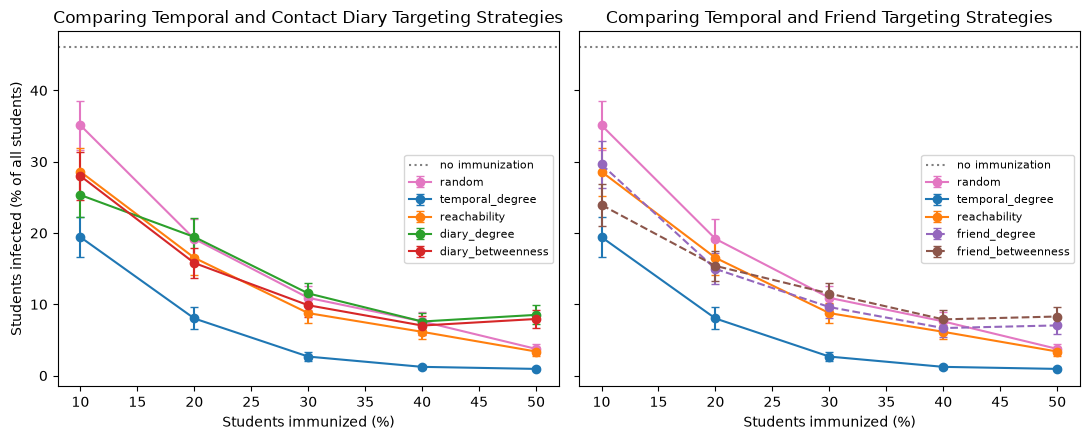

In [95]:
# assign a consistent color for each immunization strategy
colors = dict(zip(strategies, plt.cm.tab10.colors))     
# this uses the SIR similulation results when there was no immunization to establish a baseline for comparison
base_pct = np.mean(baseline) / N * 100                  

# a function defined to plot the outbreak size for a specific immunization strategy, using the summary statistics and the mean outbreak with error bars
def line(ax, strat, **kw):
    s = summary.filter(pl.col("strategy") == strat)
    ax.errorbar(s["coverage"].to_numpy() * 100, s["mean"].to_numpy() / N * 100,
                yerr=s["ci95"].to_numpy() / N * 100, marker="o", capsize=3, color=colors[strat], label=strat, **kw)


# this plots outbreak size by strategy (left: sensor-based, right: survey-based)
# creating two subplots right next to eachother
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
# iterate over the sensor strategies and plot them on the appropriate subplot, which is axes[0], specifying the left column for sensor-based strategies
for strat in ["random", "temporal_degree", "reachability", "diary_degree", "diary_betweenness"]:
    line(axes[0], strat)
# iterate over the survey based strategies and plot them on the appropriate subplot, which is axes[1], specifying the right column for survey-based strategies
for strat in ["random", "temporal_degree", "reachability", "friend_degree", "friend_betweenness"]:
    line(axes[1], strat, ls="--" if strat.startswith(("diary", "friend")) else "-")


# add an appropriate title to each subplot
for ax, title in zip(axes, ["Comparing Temporal and Contact Diary Targeting Strategies", "Comparing Temporal and Friend Targeting Strategies"]):
    # add a horizontal line indicating the baseline outbreak size with no immunization
    ax.axhline(base_pct, ls=":", color="gray", label="no immunization")
    # set the title, x-axis label, and legend for each subplot 
    ax.set_title(title); ax.set_xlabel("Students immunized (%)"); ax.legend(fontsize=8)
# set the y-axis label, which is the same for both plots
axes[0].set_ylabel("Students infected (% of all students)")
# save the figure
plt.tight_layout()
#plt.savefig("figures/fig1_outbreak_size.png", dpi=300); plt.show()